# H2O AutoML ilə Reqressiya Modelləşdirməsi (Moneyball Analizi)

Bu notebookda maşın öyrənməsi proseslərini tam avtomatlaşdıran **H2O AutoML (Automated Machine Learning)** platformasından istifadə edərək məşhur **Moneyball (Sabermetrics)** dataseti üzərində reqressiya məsələsi həll edilir. Əsas məqsəd beysbol komandasının mövsüm ərzində qazanacağı ümumi xalları (**`rs` — Runs Scored**) komandanın digər statistik göstəricilərinə əsasən yüksək dəqiqliklə proqnozlaşdırmaqdır.

---

### 1. AutoML (Automated Machine Learning) Nədir və Necə İşləyir?
Ənənəvi maşın öyrənməsi layihələrində data alimi (Data Scientist) boş dəyərlərin doldurulması, kateqorik dəyişənlərin kodlaşdırılması, onlarla fərqli alqoritmin sınaqdan keçirilməsi və hiperparametrlərin tənzimlənməsi (Grid/Random Search) üçün çox vaxt sərf edir.

**H2O AutoML** bu mərhələləri vahid boru xətti daxilində avtomatlaşdırır:
1. **Avtomatik İlkin Emal (Preprocessing):** Boş dəyərlərin (`NaN`) avtomatik doldurulması (imputation), kateqorik sütunların kodlaşdırılması (One-Hot / Target Encoding) və neyron şəbəkələri/xətti modellər üçün əlamətlərin standartlaşdırılması.
2. **Çoxsaylı Alqoritм Ailələrinin Öyrədilməsi:**
   * **GLM (Generalized Linear Models):** Elastiki cərimələmə ($L_1 + L_2$) ilə xətti reqressiya modelləri.
   * **DRF (Distributed Random Forest) & XRT (Extremely Randomized Trees):** Paylanmış təsadüfi meşə və ifrat təsadüfi ağac ansamblları.
   * **GBM (Gradient Boosting Machine) & XGBoost:** Qradiyent gücləndirmə ağacları və onların hiperparametr şəbəkəsi (Random Grid Search).
   * **Deep Learning:** Çoxqatlı tam əlaqəli süni neyron şəbəkələri (Multi-Layer Feedforward Neural Networks, Dropout və $L_1/L_2$ requlyarizasiyası ilə).
3. **Stacked Ensembles (Super Learner):** AutoML sonda ən yaxşı nəticə göstərmiş fərdi modellərin proqnozlarını birləşdirərək iki güclü meta-model qurur:
   * `StackedEnsemble_AllModels`: Öyrədilmiş bütün modellərin kombinasiyası.
   * `StackedEnsemble_BestOfFamily`: Hər alqoritm ailəsindən yalnız ən güclü 1 modelin kombinasiyası.

---

### 2. Reqressiya Modellərinin Qiymətləndirmə Metrikaları
H2O AutoML reqressiya modellərini aşağıdakı riyazi metrikalarla qiymətləndirir ($y_i$ — faktiki dəyər, $\hat{y}_i$ — proqnoz, $\bar{y}$ — faktiki dəyərlərin ortalaması):

1. **MAE (Mean Absolute Error — Orta Mütləq Xəta):**
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
   Proqnozun faktiki dəyərdən orta hesabla neçə xal (`rs`) kənarlaşdığını birbaşa göstərir. Kənarlaşmalara (outliers) qarşı dayanıqlıdır.

2. **MSE (Mean Squared Error — Orta Kvadratik Xəta):**
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
   Böyük xətaları kvadratik olaraq daha sərt cəzalandırır.

3. **RMSE (Root Mean Squared Error — Kökaltı Orta Kvadratik Xəta):**
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
   Xətanı yenidən hədəf dəyişənin (`rs`) öz ölçü vahidinə qaytarır.

4. **RMSLE (Root Mean Squared Logarithmic Error):**
   $$\text{RMSLE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left(\ln(y_i + 1) - \ln(\hat{y}_i + 1)\right)^2}$$
   Mütləq fərqdən daha çox **nisbi (faizlə) xətanı** ölçür.

5. **$R^2$ (Determinasiya Əmsalı):**
   $$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$
   Hədəf dəyişəndəki dispersiyanın (dəyişkənliyin) neçə faizinin model tərəfindən izah olunduğunu göstərir ($1.0$-ə nə qədər yaxındırsa, model bir o qədər mükəmməldir).

## 1. Lazımi Kitabxanaların Yüklənməsi

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# H2O və H2OAutoML kitabxanaları
import h2o
from h2o.automl import H2OAutoML

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

## 2. Verilənlərin Yüklənməsi və İlkin Kəşfiyyat Analizi (EDA)

`moneyball.csv` datasetində komandaların illər üzrə beysbol statistikaları toplanmışdır:
- **`team`**, **`league`**, **`year`**: Komandanın adı, liqası (`AL`/`NL`) və mövsüm ili.
- **`rs` (Runs Scored — Hədəf Dəyişən):** Komandanın mövsüm ərzində qazandığı xallar.
- **`ra` (Runs Allowed):** Rəqib komandaların bu komandaya qarşı qazandığı xallar.
- **`w` (Wins):** Mövsüm ərzində qazanılan qələbə sayı.
- **`obp` (On-Base Percentage):** Oyunçunun bazaya çıxma faizi.
- **`slg` (Slugging Percentage):** Zərbə gücü / məhsuldarlığı əmsalı.
- **`ba` (Batting Average):** Orta zərbə dəqiqliyi.
- **`playoffs`**, **`rankseason`**, **`rankplayoffs`**: Pley-offa vəsiqə və sıralama göstəriciləri.
- **`g` (Games):** Oynanılan oyun sayı.
- **`oobp` (Opponent OBP)**, **`oslg` (Opponent SLG):** Rəqibin bazaya çıxma və zərbə əmsalları.

In [4]:
data = pd.read_csv('moneyball.csv')

print(f"Datasetin ölçüsü: {data.shape[0]:,} sətir × {data.shape[1]} sütun")
data.head()

Datasetin ölçüsü: 1,232 sətir × 15 sütun


,team,league,year,rs,ra,w,obp,slg,ba,playoffs,rankseason,rankplayoffs,g,oobp,oslg
0,ARI,NL,2012,734,688,81,0.328,0.418,0.259,0,NaN,NaN,162,0.317,0.415
1,ATL,NL,2012,700,600,94,0.320,0.389,0.247,1,4.0,5.0,162,0.306,0.378
2,BAL,AL,2012,712,705,93,0.311,0.417,0.247,1,5.0,4.0,162,0.315,0.403
3,BOS,AL,2012,734,806,69,0.315,0.415,0.260,0,NaN,NaN,162,0.331,0.428
4,CHC,NL,2012,613,759,61,0.302,0.378,0.240,0,NaN,NaN,162,0.335,0.424


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1232 entries, 0 to 1231
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   team          1232 non-null   object 
 1   league        1232 non-null   object 
 2   year          1232 non-null   int64  
 3   rs            1232 non-null   int64  
 4   ra            1232 non-null   int64  
 5   w             1232 non-null   int64  
 6   obp           1232 non-null   float64
 7   slg           1232 non-null   float64
 8   ba            1232 non-null   float64
 9   playoffs      1232 non-null   int64  
 10  rankseason    244 non-null    float64
 11  rankplayoffs  244 non-null    float64
 12  g             1232 non-null   int64  
 13  oobp          420 non-null    float64
 14  oslg          420 non-null    float64
dtypes: float64(7), int64(6), object(2)
memory usage: 144.5+ KB


### Boş Dəyərlərin (`NaN`) Analizi

Sütunlardakı çatışmayan dəyərlərin sayını və faizini yoxlayaq:
- `rankseason` və `rankplayoffs` sütunlarında **80.2% boş dəyər** var, çünki yalnız pley-off mərhələsinə yüksələn (`playoffs == 1`) komandalar üçün bu sıralama mövcuddur.
- `oobp` və `oslg` sütunlarında isə **65.9% boş dəyər** var, çünki bu statistikalar yalnız 1999-cu ildən etibarən qeydə alınmağa başlanmışdır.

> [!NOTE]
> **H2O-nun Boş Dəyərlərlə İşləmə Üstünlüyü:** `scikit-learn` modellərindən fərqli olaraq, H2O alqoritmləri `NaN` dəyərləri xəta vermədən avtomatik emal edir (ağac modellərində `NaN` ayrıca budaqlanma istiqaməti kimi qəbul edilir, xətti və neyron şəbəkə modellərində isə avtomatik orta dəyərlə əvəzlənir və ya ayrıca indikator sütunu yaradılır).

In [4]:
# Boş dəyərlərin sayı və faiz nisbəti
missing_count = data.isna().sum()
missing_pct = (missing_count / len(data) * 100).round(2)

missing_df = pd.DataFrame({
    'Boş Dəyər Sayı (NaN)': missing_count,
    'Boş Dəyər Faizi (%)': missing_pct,
    'Dolu Dəyər Sayı': data.notna().sum(),
    'Məlumat Tipi': data.dtypes
})

missing_df

,Boş Dəyər Sayı (NaN),Boş Dəyər Faizi (%),Dolu Dəyər Sayı,Məlumat Tipi
team,0,0.00,1232,object
league,0,0.00,1232,object
year,0,0.00,1232,int64
rs,0,0.00,1232,int64
ra,0,0.00,1232,int64
w,0,0.00,1232,int64
obp,0,0.00,1232,float64
slg,0,0.00,1232,float64
ba,0,0.00,1232,float64
playoffs,0,0.00,1232,int64


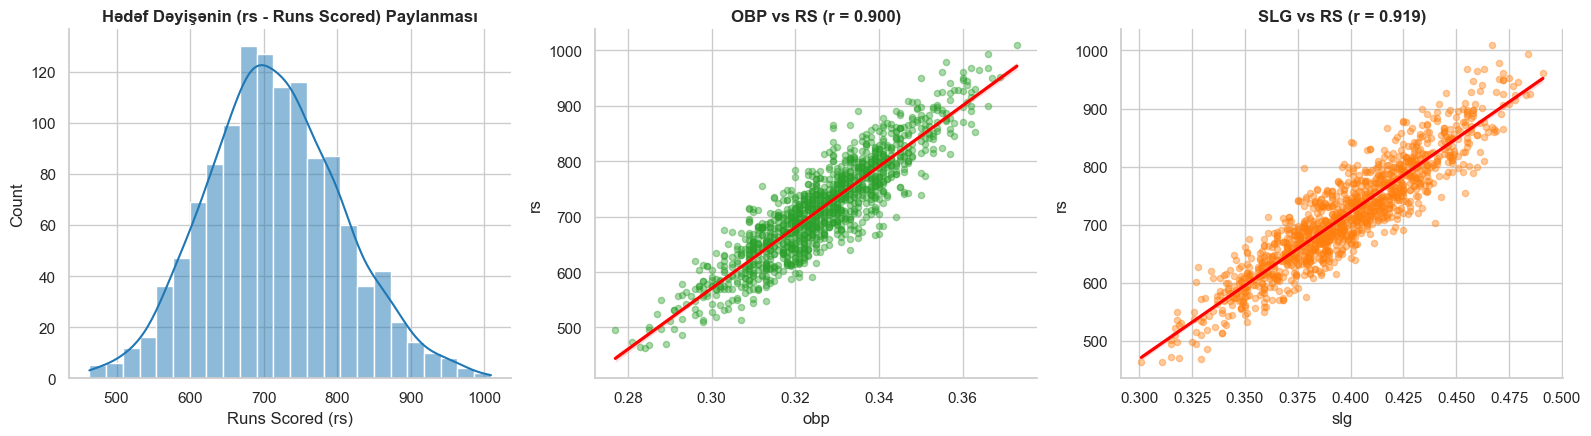

In [5]:
# Hədəf dəyişən (rs) ilə əsas hücum göstəriciləri (obp, slg, ba) arasındakı korrelyasiya və paylanma
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(data['rs'], kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title('Hədəf Dəyişənin (rs - Runs Scored) Paylanması', fontweight='bold')
axes[0].set_xlabel('Runs Scored (rs)')

sns.regplot(data=data, x='obp', y='rs', ax=axes[1], color='#2ca02c', scatter_kws={'alpha': 0.4, 's': 20}, line_kws={'color': 'red'})
axes[1].set_title(f"OBP vs RS (r = {data['obp'].corr(data['rs']):.3f})", fontweight='bold')

sns.regplot(data=data, x='slg', y='rs', ax=axes[2], color='#ff7f0e', scatter_kws={'alpha': 0.4, 's': 20}, line_kws={'color': 'red'})
axes[2].set_title(f"SLG vs RS (r = {data['slg'].corr(data['rs']):.3f})", fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()

---
## 3. H2O Klasterinin Başladılması və `H2OFrame` Yaradılması

H2O yaddaş-daxili (in-memory), paylanmış Java Virtual Maşını (JVM) üzərində işləyir:
1. `h2o.init()` funksiyası lokal kompüterdə H2O serverini (`http://127.0.0.1:54321`) işə salır.
2. Standart `pandas.DataFrame` obyekti `h2o.H2OFrame(data)` vasitəsilə H2O-nun yüksək sürətli sıxılmış sütunlu formatına (`H2OFrame`) çevrilir.

In [6]:
# Lokal H2O klasterini işə salırıq
h2o.init()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.501-b08, mixed mode)
  Starting server from C:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\ayna\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\TARLAN~1.CAB\AppData\Local\Temp\tmp53e5wxw_
  JVM stdout: C:\Users\TARLAN~1.CAB\AppData\Local\Temp\tmp53e5wxw_\h2o_tarlan_cabiyev_started_from_python.out
  JVM stderr: C:\Users\TARLAN~1.CAB\AppData\Local\Temp\tmp53e5wxw_\h2o_tarlan_cabiyev_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,04 secs
H2O_cluster_timezone:,Europe/Berlin
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.11
H2O_cluster_version_age:,5 months and 6 days
H2O_cluster_name:,H2O_from_python_tarlan_cabiyev_op33oy
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,7.024 Gb
H2O_cluster_total_cores:,20
H2O_cluster_allowed_cores:,20
H2O_cluster_status:,"locked, healthy"


In [7]:
# Pandas DataFrame-i H2OFrame obyektinə çeviririk
h2o_data = h2o.H2OFrame(data)
print(f"Obyektin tipi: {type(h2o_data)} | Ölçüsü: {h2o_data.shape}")

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Obyektin tipi: <class 'h2o.frame.H2OFrame'> | Ölçüsü: (1232, 15)


---
## 4. Verilənlərin Bölünməsi (Train / Validation / Test Split) və Əlamətlərin Təyini

`split_frame(ratios=[0.8, 0.1], seed=123)` metodu verilənləri təsadüfi (lakin `seed=123` sayəsində təkrarolunan) şəkildə **3 hissəyə** ayırır:
- **Train (~80%):** Modellərin öyrədilməsi və 5-qat çarpaz doğrulama (5-Fold Cross-Validation) üçün.
- **Validation (~10%):** Təlim zamanı aralıq yoxlama metrikalarını izləmək üçün.
- **Test (~10%):** Təlim prosesində heç vaxt istifadə olunmayan, yekun Liderlər Cədvəlini (`leaderboard_frame`) sıralamaq və obyektiv test performansını ölçmək üçün.

In [8]:
# Datanın 80% Train, 10% Validation və 10% Test olaraq bölünməsi
train, valid, test = h2o_data.split_frame(ratios=[0.8, 0.1], seed=123)

print(f"Train sətir sayı      : {train.nrow:,} ({train.nrow / h2o_data.nrow * 100:.1f}%)")
print(f"Validation sətir sayı : {valid.nrow:,} ({valid.nrow / h2o_data.nrow * 100:.1f}%)")
print(f"Test sətir sayı       : {test.nrow:,} ({test.nrow / h2o_data.nrow * 100:.1f}%)")

Train sətir sayı      : 978 (79.4%)
Validation sətir sayı : 140 (11.4%)
Test sətir sayı       : 114 (9.3%)


In [9]:
# Hədəf dəyişən (target) və müstəqil dəyişənlərin (features) siyahısı
target = 'rs'
features = data.drop(columns=[target]).columns.to_list()

print(f"Hədəf dəyişən (y)       : '{target}'")
print(f"Giriş əlamətləri (x, {len(features)}) : {features}")

Hədəf dəyişən (y)       : 'rs'
Giriş əlamətləri (x, 14) : ['team', 'league', 'year', 'ra', 'w', 'obp', 'slg', 'ba', 'playoffs', 'rankseason', 'rankplayoffs', 'g', 'oobp', 'oslg']


---
## 5. H2O AutoML Modelinin Qurulması və Öyrədilməsi

`H2OAutoML` obyektini yaradarkən istifadə etdiyimiz əsas hiperparametrlər:
- **`stopping_metric = "mae"`**: Modellərin erkən dayandırılması (Early Stopping) zamanı əsas meyar kimi **Orta Mütləq Xəta (MAE)** götürülür.
- **`sort_metric = "mae"` (və ya default `AUTO`/`rmse`)**: Liderlər cədvəlinin hansı metrikaya görə sıralanacağını müəyyən edir.
- **`nfolds = 5`**: Hər bir model `train` dəsti üzərində **5-qat Çarpaz Doğrulama (5-Fold Cross-Validation)** ilə yoxlanılır və bu CV proqnozları əsasında **Stacked Ensemble** modelləri qurulur.
- **`max_runtime_secs = 180`**: AutoML axtarışına maksimum $180$ saniyə ($3$ dəqiqə) vaxt limiti qoyulur.
- **`seed = 123`**: Nəticələrin təkrarolunanlığını təmin edir.

> [!TIP]
> **Qeyd (`validation_frame` + `nfolds=5` haqqında):** H2O-da `nfolds=5` aktiv olduqda modellərin optimallaşdırılması və seçimi birbaşa 5-qat çarpaz doğrulama (CV) üzərindən aparılır, `validation_frame` isə əlavə məlumatlandırıcı hesabat üçün istifadə olunur. `leaderboard_frame = test` verildiyi üçün yekun liderlər cədvəli birbaşa **Test** dəstindəki performansa görə sıralanır.

In [10]:
# AutoML konfiqurasiyası
model = H2OAutoML(
    stopping_metric="mae",
    nfolds=5,
    seed=123,
    max_runtime_secs=180
)

# Modellərin avtomatik öyrədilməsi
model.train(
    x=features,
    y=target,
    training_frame=train,
    validation_frame=valid,
    leaderboard_frame=test
)

AutoML progress: |
13:16:36.652: User specified a validation frame with cross-validation still enabled. Please note that the models will still be validated using cross-validation only, the validation frame will be used to provide purely informative validation metrics on the trained models.
13:16:36.665: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%


key,value
Stacking strategy,cross_validation
Number of base models (used / total),11/41
# GBM base models (used / total),5/28
# DeepLearning base models (used / total),4/10
# DRF base models (used / total),1/2
# GLM base models (used / total),1/1
Metalearner algorithm,GLM
Metalearner fold assignment scheme,Random
Metalearner nfolds,5
Metalearner fold_column,None


---
## 6. Liderlər Cədvəli (Leaderboard) və Ən Yaxşı Modelin (`leader`) Analizi

In [ ]:
lb_df = model.leaderboard.as_data_frame()

print(f"AutoML tərəfindən öyrədilmiş ümumi model sayı: {len(lb_df)}")
lb_df.head(10)

AutoML tərəfindən öyrədilmiş ümumi model sayı: 70


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,StackedEnsemble_AllModels_3_AutoML_1_20261028_...,23.769092,564.969737,19.642461,0.033469,564.969737
1,StackedEnsemble_Best1000_1_AutoML_1_20261028_1...,23.982055,575.138959,20.337955,0.033676,575.138959
2,StackedEnsemble_AllModels_4_AutoML_1_20261028_...,24.093611,580.502068,20.351718,0.033799,580.502068
3,DeepLearning_1_AutoML_1_20261028_131636,24.108210,581.205794,19.745016,0.033954,581.205794
4,StackedEnsemble_AllModels_6_AutoML_1_20261028_...,24.121951,581.868534,20.342442,0.033832,581.868534
5,DeepLearning_grid_1_AutoML_1_20261028_131636_m...,24.178720,584.610504,20.253481,0.034369,584.610504
6,StackedEnsemble_BestOfFamily_4_AutoML_1_202610...,24.393368,595.036388,20.291183,0.034371,595.036388
7,StackedEnsemble_BestOfFamily_6_AutoML_1_202610...,24.433127,596.977715,20.297578,0.034421,596.977715
8,StackedEnsemble_BestOfFamily_3_AutoML_1_202610...,24.755602,612.839820,20.509859,0.034833,612.839820
9,StackedEnsemble_AllModels_2_AutoML_1_20261028_...,24.835375,616.795862,20.672834,0.034946,616.795862


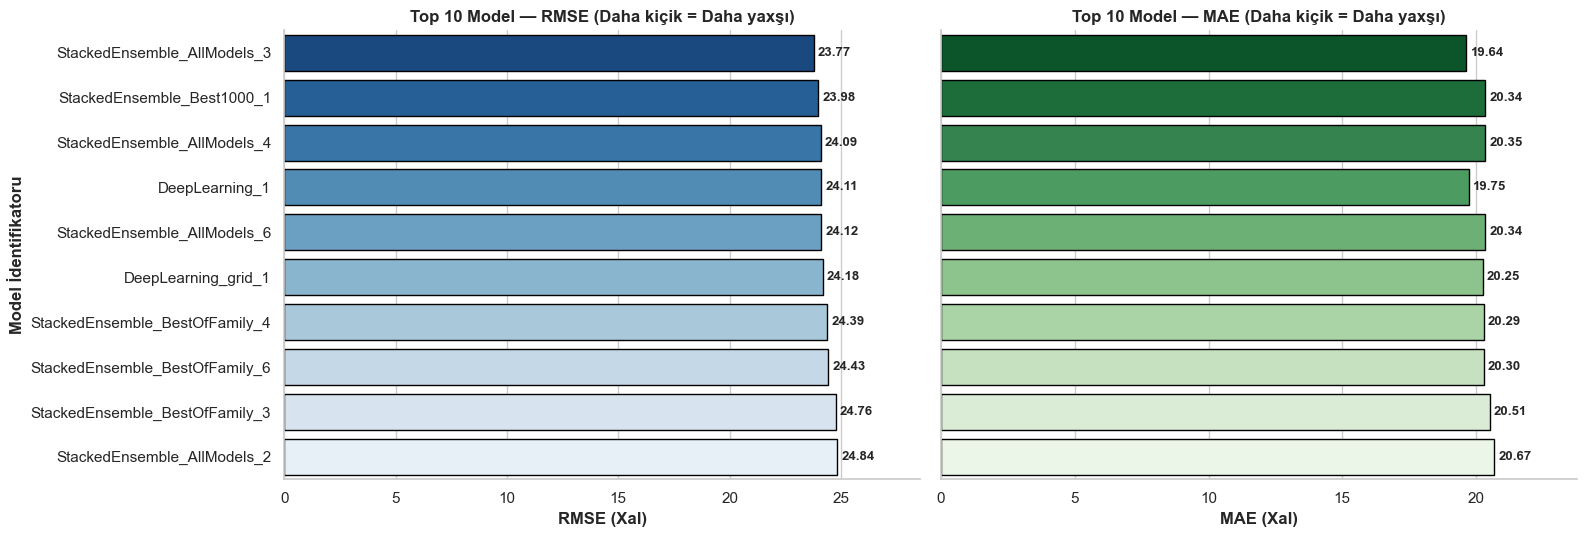

In [14]:
# Ən yaxşı 10 modelin RMSE və MAE metrikalarının vizual müqayisəsi
top10_lb = lb_df.head(10).copy()
# Model adlarını qrafikdə oxunaqlı etmək üçün qısaldırıq
top10_lb['short_name'] = top10_lb['model_id'].apply(lambda s: s.split('_AutoML')[0])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)

sns.barplot(data=top10_lb, x='rmse', y='short_name', hue='short_name', palette='Blues_r', legend=False, ax=axes[0], edgecolor='black')
axes[0].set_title('Top 10 Model — RMSE (Daha kiçik = Daha yaxşı)', fontweight='bold')
axes[0].set_xlabel('RMSE (Xal)', fontweight='bold')
axes[0].set_ylabel('Model İdentifikatoru', fontweight='bold')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontsize=9.5, fontweight='bold')
axes[0].set_xlim(0, top10_lb['rmse'].max() * 1.15)

sns.barplot(data=top10_lb, x='mae', y='short_name', hue='short_name', palette='Greens_r', legend=False, ax=axes[1], edgecolor='black')
axes[1].set_title('Top 10 Model — MAE (Daha kiçik = Daha yaxşı)', fontweight='bold')
axes[1].set_xlabel('MAE (Xal)', fontweight='bold')
axes[1].set_ylabel('')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontsize=9.5, fontweight='bold')
axes[1].set_xlim(0, top10_lb['mae'].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

In [15]:
# Lider modelin seçilməsi və detallı arxitekturası
best_model = model.leader
best_model

key,value
Stacking strategy,cross_validation
Number of base models (used / total),11/41
# GBM base models (used / total),5/28
# DeepLearning base models (used / total),4/10
# DRF base models (used / total),1/2
# GLM base models (used / total),1/1
Metalearner algorithm,GLM
Metalearner fold assignment scheme,Random
Metalearner nfolds,5
Metalearner fold_column,None


---
## 7. Reqressiya Modelinin Performansının Hərtərəfli Qiymətləndirilməsi

Modelin **ifrat öyrənməyə (overfitting)** məruz qalıb-qalmadığını yoxlamaq üçün onun performansını bütün 4 məlumat kəsiyində müqayisə edirik:
1. **Train (`train=True`):** Modelin öyrəndiyi dəst üzərindəki dəqiqliyi.
2. **Validation (`valid=True`):** Təlim zamanı istifadə olunan validasiya dəsti üzərindəki dəqiqliyi.
3. **Cross-Validation (`xval=True`):** 5-qat çarpaz doğrulama üzrə orta ümumiləşdirmə dəqiqliyi.
4. **Test (`test`):** Tamamilə görünməmiş test dəsti üzərindəki yekun real dəqiqliyi.

In [16]:
# Ayrı-ayrılıqda R² göstəriciləri
r2_train = best_model.model_performance(train=True).r2()
r2_valid = best_model.model_performance(valid=True).r2()
r2_xval  = best_model.model_performance(xval=True).r2()
r2_test  = best_model.model_performance(test).r2()

print(f"Train R²            : {r2_train:.4f}")
print(f"Validation R²       : {r2_valid:.4f}")
print(f"Cross-Validation R² : {r2_xval:.4f}")
print(f"Test R²             : {r2_test:.4f}")

Train R²            : 0.9790
Validation R²       : 0.9562
Cross-Validation R² : 0.9427
Test R²             : 0.9252


In [18]:
# Bütün dəstlər üzrə bütün reqressiya metrikalarının vahid müqayisə cədvəli
perf_splits = {
    '1. Train': best_model.model_performance(train=True),
    '2. Validation': best_model.model_performance(valid=True),
    '3. Cross-Validation (5-Fold)': best_model.model_performance(xval=True),
    '4. Test (Unseen)': best_model.model_performance(test)
}

metrics_Comparison = pd.DataFrame([
    {
        'Məlumat Dəsti': split_name,
        'R²': perf.r2(),
        'RMSE': perf.rmse(),
        'MAE': perf.mae(),
        'MSE': perf.mse(),
    }
    for split_name, perf in perf_splits.items()
]).set_index('Məlumat Dəsti').round(4)

metrics_Comparison

,R²,RMSE,MAE,MSE
Məlumat Dəsti,,,,
1. Train,0.9790,13.2119,10.1256,174.5551
2. Validation,0.9562,20.3182,16.4142,412.8278
3. Cross-Validation (5-Fold),0.9427,21.8255,17.0453,476.3516
4. Test (Unseen),0.9252,23.7691,19.6425,564.9697


In [19]:
# Ən yaxşı model üzrə dəyişənlərin əhəmiyyətlilik dərəcəsi (Variable Importance - Top 15)
if best_model.varimp() is not None:
    varimp_df = best_model.varimp(use_pandas=True).head(15)
    plt.figure(figsize=(10, 5.5))
    ax = sns.barplot(data=varimp_df, x='scaled_importance', y='variable', hue='variable', palette='magma', legend=False, edgecolor='black')
    plt.title(f'Ən Əhəmiyyətli 15 Dəyişən ({best_model.model_id})', fontweight='bold', fontsize=12)
    plt.xlabel('Nisbi Əhəmiyyətlilik (Scaled Importance: 0 - 1)', fontweight='bold')
    plt.ylabel('Dəyişən (Feature)', fontweight='bold')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)
    plt.xlim(0, 1.12)
    sns.despine()
    plt.tight_layout()
    plt.show()

---
## 8. Test Dəsti Üzərində Proqnozlar və Xəta (Residual) Analizi

Seçilmiş ən güclü model (`best_model`) vasitəsilə `test` dəstindəki komandaların qazanacağı xalları (`predict`) proqnozlaşdırırıq və faktiki `rs` dəyərləri ilə müqayisə edirik.

In [20]:
# Test dəsti üzrə proqnozların alınması
y_pred = best_model.predict(test).as_data_frame()
pred = y_pred['predict']
pred

stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%


0      769.899738
1      769.804936
2      633.964144
3      688.478106
4      814.836622
          ...    
109    655.484635
110    586.100213
111    477.060466
112    578.580820
113    698.045757
Name: predict, Length: 114, dtype: float64